In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
print("GPU Available:", tf.config.list_physical_devices('GPU'))

GPU Available: []


In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 807s 5us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


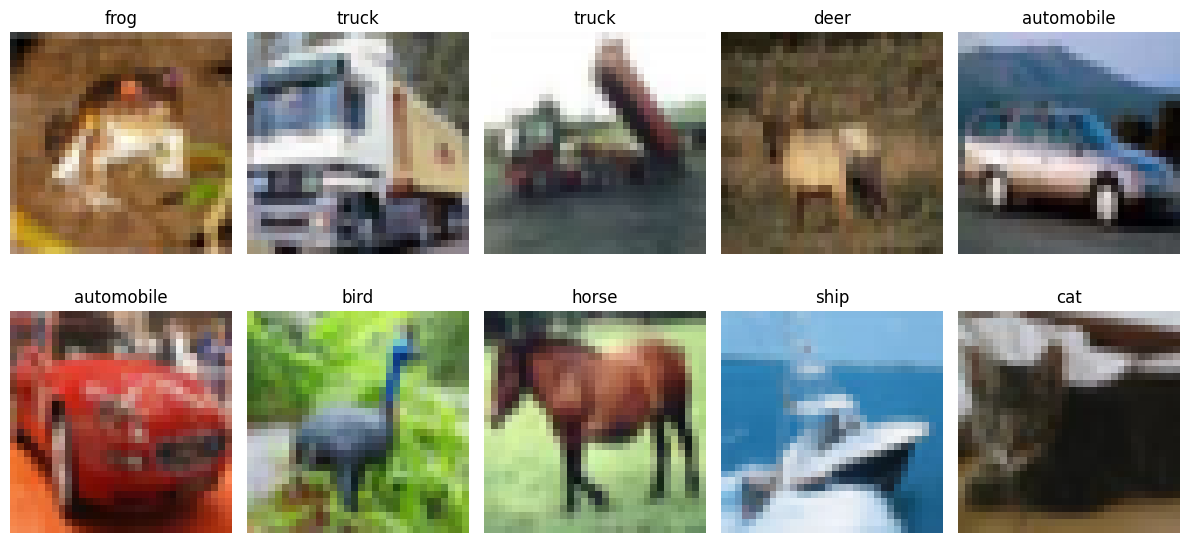

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

data_augmentation

<Sequential name=data_augmentation, built=False>

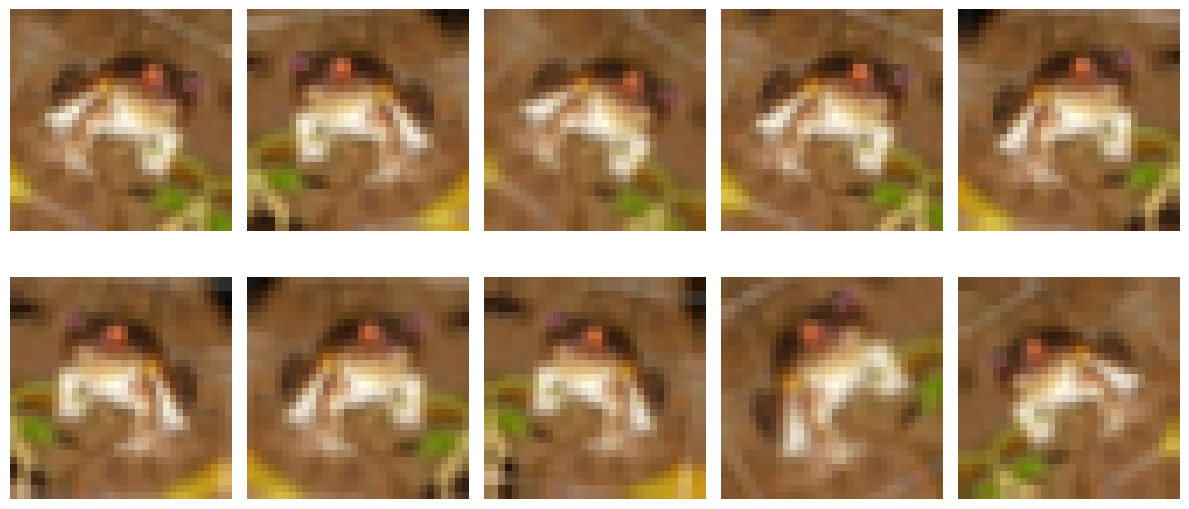

In [ ]:
plt.figure(figsize=(12, 6))

sample_image = x_train[0]
sample_image = tf.expand_dims(sample_image, axis=0)

for i in range(10):
    augmented_image = data_augmentation(sample_image, training=True)

    plt.subplot(2, 5, i + 1)
    plt.imshow(augmented_image[0])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(10, activation="softmax")
])

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
start_time = time.time()

mlp_history = mlp_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)

mlp_training_time = time.time() - start_time

print(f"MLP Training Time: {mlp_training_time:.2f} seconds")

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.2515 - loss: 2.0518 - val_accuracy: 0.3174 - val_loss: 1.8927
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.3131 - loss: 1.8854 - val_accuracy: 0.3552 - val_loss: 1.7885
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.3283 - loss: 1.8455 - val_accuracy: 0.3670 - val_loss: 1.7900
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.3453 - loss: 1.8022 - val_accuracy: 0.3862 - val_loss: 1.7309
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.3545 - loss: 1.7762 - val_accuracy: 0.3938 - val_loss: 1.7190
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.3620 - loss: 1.7582 - val_accuracy: 0.3816 - val_loss: 1.7109
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.3642 - loss: 1.7458 - val_accuracy: 0.4128 - val_loss: 1.6843
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.3705 - loss: 1.7409 - 

In [ ]:
mlp_test_loss, mlp_test_accuracy = mlp_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("MLP Test Loss:", mlp_test_loss)
print("MLP Test Accuracy:", mlp_test_accuracy)
print("MLP Test Accuracy (%):", mlp_test_accuracy * 100)

MLP Test Loss: 1.6318968534469604
MLP Test Accuracy: 0.4235000014305115
MLP Test Accuracy (%): 42.35000014305115


In [ ]:
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    # Data augmentation
    data_augmentation,

    # Convolution block 1
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.40),
    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
start_time = time.time()

cnn_history = cnn_model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)

cnn_training_time = time.time() - start_time

print(f"CNN Training Time: {cnn_training_time:.2f} seconds")

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 78s 217ms/step - accuracy: 0.3631 - loss: 1.7544 - val_accuracy: 0.4642 - val_loss: 1.5037
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 74s 211ms/step - accuracy: 0.4575 - loss: 1.5060 - val_accuracy: 0.5506 - val_loss: 1.2460
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 212ms/step - accuracy: 0.4972 - loss: 1.4077 - val_accuracy: 0.5670 - val_loss: 1.2103
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 212ms/step - accuracy: 0.5199 - loss: 1.3494 - val_accuracy: 0.5946 - val_loss: 1.1372
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 210ms/step - accuracy: 0.5344 - loss: 1.3057 - val_accuracy: 0.6030 - val_loss: 1.1122
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 75s 212ms/step - accuracy: 0.5437 - loss: 1.2750 - val_accuracy: 0.6230 - val_loss: 1.0818
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 73s 208ms/step - accuracy: 0.5608 - loss: 1.2443 - val_accuracy: 0.6216 - val_loss: 1.0779
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 83s 210ms/step - accuracy: 0.5720 - loss: 1

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)
print("CNN Test Accuracy (%):", cnn_test_accuracy * 100)

CNN Test Loss: 1.1037465333938599
CNN Test Accuracy: 0.6195999979972839
CNN Test Accuracy (%): 61.959999799728394


In [ ]:
print("=" * 50)
print("FINAL RESULTS")
print("=" * 50)

print(f"MLP Test Accuracy  : {mlp_test_accuracy * 100:.2f}%")
print(f"CNN Test Accuracy  : {cnn_test_accuracy * 100:.2f}%")

print()

print(f"MLP Test Loss      : {mlp_test_loss:.4f}")
print(f"CNN Test Loss      : {cnn_test_loss:.4f}")

print()

print(f"MLP Training Time  : {mlp_training_time:.2f} seconds")
print(f"CNN Training Time  : {cnn_training_time:.2f} seconds")

FINAL RESULTS
MLP Test Accuracy  : 42.35%
CNN Test Accuracy  : 61.96%

MLP Test Loss      : 1.6319
CNN Test Loss      : 1.1037

MLP Training Time  : 154.86 seconds
CNN Training Time  : 794.66 seconds


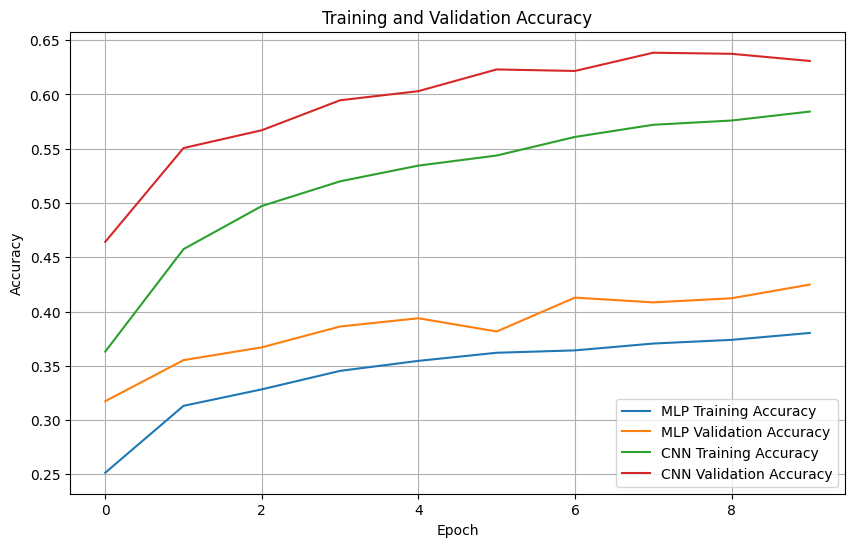

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    mlp_history.history["accuracy"],
    label="MLP Training Accuracy"
)

plt.plot(
    mlp_history.history["val_accuracy"],
    label="MLP Validation Accuracy"
)

plt.plot(
    cnn_history.history["accuracy"],
    label="CNN Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="CNN Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

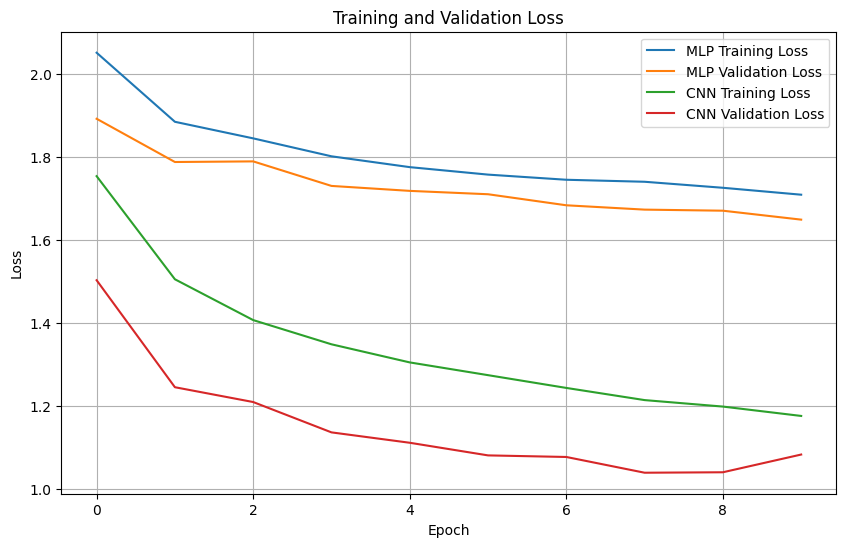

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    mlp_history.history["loss"],
    label="MLP Training Loss"
)

plt.plot(
    mlp_history.history["val_loss"],
    label="MLP Validation Loss"
)

plt.plot(
    cnn_history.history["loss"],
    label="CNN Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="CNN Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
predictions = cnn_model.predict(x_test[:10], verbose=0)

predicted_classes = np.argmax(predictions, axis=1)

print("Actual classes   :", [class_names[i] for i in y_test[:10]])
print("Predicted classes:", [class_names[i] for i in predicted_classes])

Actual classes   : ['cat', 'ship', 'ship', 'airplane', 'frog', 'frog', 'automobile', 'frog', 'cat', 'automobile']
Predicted classes: ['cat', 'automobile', 'ship', 'airplane', 'frog', 'frog', 'automobile', 'bird', 'cat', 'automobile']


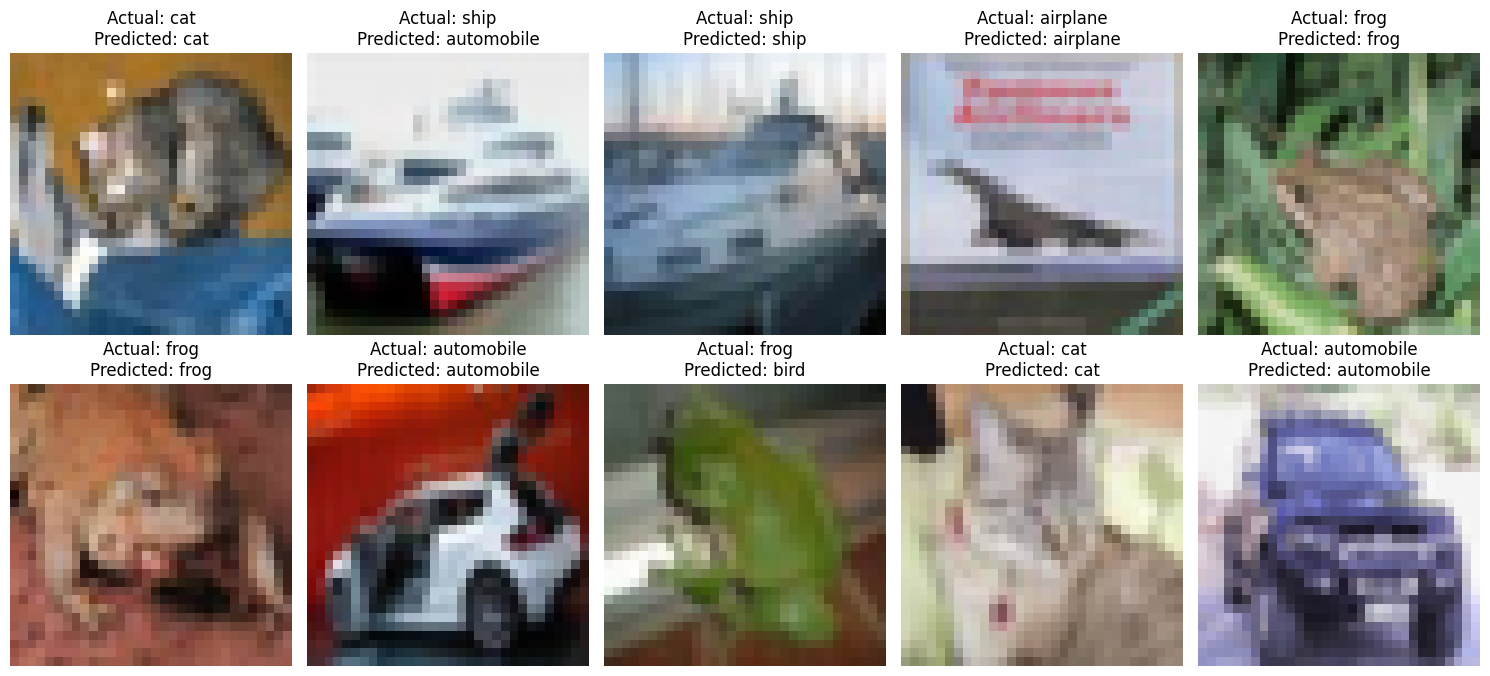

In [ ]:
plt.figure(figsize=(15, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i])

    actual = class_names[y_test[i]]
    predicted = class_names[predicted_classes[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

observation_table = pd.DataFrame({
    "Parameter": [
        "Test accuracy (%)",
        "Test loss",
        "Training time (seconds)",
        "Number of epochs",
        "Batch size",
        "Data augmentation",
        "Validation split"
    ],

    "MLP": [
        f"{mlp_test_accuracy * 100:.2f}",
        f"{mlp_test_loss:.4f}",
        f"{mlp_training_time:.2f}",
        10,
        128,
        "No",
        "10%"
    ],

    "CNN": [
        f"{cnn_test_accuracy * 100:.2f}",
        f"{cnn_test_loss:.4f}",
        f"{cnn_training_time:.2f}",
        10,
        128,
        "Yes",
        "10%"
    ]
})

observation_table

,Parameter,MLP,CNN
0,Test accuracy (%),42.35,61.96
1,Test loss,1.6319,1.1037
2,Training time (seconds),154.86,794.66
3,Number of epochs,10,10
4,Batch size,128,128
5,Data augmentation,No,Yes
6,Validation split,10%,10%


In [ ]:
print("\n" + "=" * 60)
print("OBSERVATION TABLE")
print("=" * 60)

print(f"{'Parameter':<30} {'MLP':<15} {'CNN':<15}")
print("-" * 60)

print(
    f"{'Test accuracy (%)':<30} "
    f"{mlp_test_accuracy * 100:<15.2f} "
    f"{cnn_test_accuracy * 100:<15.2f}"
)

print(
    f"{'Test loss':<30} "
    f"{mlp_test_loss:<15.4f} "
    f"{cnn_test_loss:<15.4f}"
)

print(
    f"{'Training time (seconds)':<30} "
    f"{mlp_training_time:<15.2f} "
    f"{cnn_training_time:<15.2f}"
)

print(
    f"{'Number of epochs':<30} "
    f"{'10':<15} "
    f"{'10':<15}"
)

print(
    f"{'Batch size':<30} "
    f"{'128':<15} "
    f"{'128':<15}"
)

print(
    f"{'Data augmentation':<30} "
    f"{'No':<15} "
    f"{'Yes':<15}"
)

print(
    f"{'Validation split':<30} "
    f"{'10%':<15} "
    f"{'10%':<15}"
)

print("=" * 60)


OBSERVATION TABLE
Parameter                      MLP             CNN            
------------------------------------------------------------
Test accuracy (%)              42.35           61.96          
Test loss                      1.6319          1.1037         
Training time (seconds)        154.86          794.66         
Number of epochs               10              10             
Batch size                     128             128            
Data augmentation              No              Yes            
Validation split               10%             10%            
